# 04 · Cifras ponderadas con intervalos de confianza

**Responsable:** Magno Luque · **Proyecto:** YAWAR (Hackathon FACI 2026, UPCH)

## Para qué sirve este cuaderno
Hasta ahora todas las cifras eran **sin ponderar**: describían a los niños que entraron a la encuesta, no a los niños del Perú. Aquí calculamos las cifras **ponderadas**, que sí representan a la población y son las únicas que pueden ir al pitch y a la ficha. Cada cifra trae su **intervalo de confianza del 95 %**.

Calcula:
1. Qué porcentaje de niños de 6 a 35 meses **recibió** hierro, y cuántos lo **tomaron** la última semana.
2. El grupo clave del proyecto: los que **recibieron hierro y no lo tomaron**.
3. Las **razones** por las que no se consumió todo lo recibido.
4. La **anemia**, con las dos definiciones oficiales, para respaldar la frase "la anemia casi no bajó entre 2024 y 2025".
5. La **diferencia 2024 → 2025** de cada cifra, con su intervalo.

> **Regla de oro del proyecto:** toda cifra dice si está ponderada, de qué año y de qué edades. En este cuaderno todo es **ponderado**, de **niños de 6 a 35 meses**, salvo que se indique otra cosa.

## Cómo se pondera (explicación simple)
- **Factor de expansión:** cada niño "representa" a cierta cantidad de niños del país; el peso es el factor dividido entre 1 000 000 (así lo indica la ficha técnica de ENDES).
- **Dos factores distintos:** la ficha técnica indica el factor **hogar** (`HV005`) para **anemia** en menores de 5 años, y el factor **mujer** (`V005`) para indicadores del cuestionario individual. Usamos el factor hogar en anemia y el factor mujer en hierro. Como la ficha no dice qué factor corresponde a hierro, en la sección 5 comprobamos cuánto cambia el resultado si se usa el otro.
- **Estrato y conglomerado:** ENDES visita zonas (conglomerados) dentro de estratos. Niños de la misma zona se parecen entre sí, así que la encuesta "vale" menos que si fueran niños sueltos. El intervalo de confianza lo tiene en cuenta; por eso es más ancho que el de una muestra simple.
- **Efecto de diseño (deff):** cuántas veces es mayor la varianza respecto a una muestra simple. Un deff de 3 significa que la encuesta equivale a tener 3 veces menos niños.

> No calculamos **totales** (por ejemplo, "cuántos niños en el Perú..."), solo **porcentajes**. Para totales haría falta verificar con más cuidado el tamaño de los factores.

In [1]:
import sys, math
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
from rutas import RAIZ

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

CARPETA = RAIZ / "datos_procesados"
RESULTADOS = RAIZ / "analisis" / "resultados"
faltan = [a for a in (2024, 2025) if not (CARPETA / f"tabla_nino_{a}.csv").exists()]
assert not faltan, f"Falta la tabla de {faltan}. Ejecuta primero el cuaderno 03."

tablas = {a: pd.read_csv(CARPETA / f"tabla_nino_{a}.csv", low_memory=False) for a in (2024, 2025)}
for a, d in tablas.items():
    print(f"{a}: {len(d)} niños, {d['conglomerado'].nunique()} conglomerados, {d['estrato'].nunique()} estratos")

2024: 19751 niños, 3228 conglomerados, 240 estratos
2025: 18841 niños, 3207 conglomerados, 240 estratos


## 1. El estimador
Implementamos el método estándar para encuestas con estratos y conglomerados (linealización de Taylor, el mismo que usan `survey` en R o `svy` en Stata). Las piezas:

- **Proporción ponderada** = suma de pesos de quienes cumplen / suma de pesos del grupo.
- **Error estándar** = se calcula con la variación *entre conglomerados* dentro de cada estrato.
- **Intervalo del 95 %**: se calcula en escala logit (como hace Stata por defecto) para que nunca salga de 0 a 100, con los grados de libertad del diseño (conglomerados − estratos).
- **Subpoblaciones** (por ejemplo "rural" o "12-23 meses"): se estima con *toda* la muestra y un indicador del grupo, no recortando la tabla. Es la forma correcta para que el error estándar sea válido.

Como este código es nuestro, **lo probamos** antes de usarlo (sección siguiente).

In [2]:
# El estimador vive en analisis/encuestas.py: los cuadernos 04 y 05 usan exactamente el mismo código.
from encuestas import Z975, t_cuantil_975, normal_cdf, Diseno, REGIONES, grupos, calcular, ver, error_estandar_jackknife, diferencias
print("Estimador cargado desde analisis/encuestas.py (clase Diseno, método proporcion).")

Estimador cargado desde analisis/encuestas.py (clase Diseno, método proporcion).


### Pruebas del estimador
Antes de usarlo, comprobamos que reproduce casos donde la respuesta correcta se conoce de antemano. Si alguna falla, el cuaderno se detiene.

In [3]:
rng = np.random.default_rng(1)

# Prueba 1: con pesos iguales y cada niño como su propio conglomerado (muestra simple),
# el error estándar debe ser la fórmula clásica de una proporción.
n = 500
y = rng.integers(0, 2, n)
juguete = pd.DataFrame({"y": y, "peso": 1_000_000, "estrato": 1, "conglomerado": np.arange(n)})
r = Diseno(juguete, "peso").proporcion(juguete["y"], np.ones(n, bool))
p = y.mean()
se_clasico = math.sqrt(p * (1 - p) / n * n / (n - 1))
assert abs(r["estimacion"] / 100 - p) < 1e-12, "la proporción no coincide"
assert abs(r["se"] / 100 - se_clasico) < 1e-10, "el error estándar no coincide con la fórmula clásica"

# Prueba 2: multiplicar todos los pesos por una constante no cambia nada.
juguete2 = juguete.assign(peso=juguete["peso"] * 7.3)
r2 = Diseno(juguete2, "peso").proporcion(juguete2["y"], np.ones(n, bool))
assert abs(r2["estimacion"] - r["estimacion"]) < 1e-9 and abs(r2["se"] - r["se"]) < 1e-9, "no es invariante a la escala"

# Prueba 3: en una subpoblación, dos formas de calcular deben coincidir si el grupo es toda la muestra.
mitad = np.arange(n) < n // 2
rd = Diseno(juguete, "peso").proporcion(juguete["y"], mitad)
assert abs(rd["estimacion"] / 100 - y[: n // 2].mean()) < 1e-12, "falla la estimación en subpoblación"

# Prueba 4: cuantil t conocido (tablas): gl=30 -> 2,0423 ; gl=120 -> 1,9799
assert abs(t_cuantil_975(30) - 2.0423) < 1e-3 and abs(t_cuantil_975(120) - 1.9799) < 1e-3, "cuantil t incorrecto"

# Prueba 5: conglomerados con datos muy parecidos entre sí deben dar MÁS incertidumbre que muestra simple (deff > 1)
g = np.repeat(np.arange(50), 20)
yg = (rng.random(50)[g] > 0.5).astype(int)     # todos los niños de un conglomerado responden igual
agrup = pd.DataFrame({"y": yg, "peso": 1_000_000, "estrato": 1, "conglomerado": g})
ra = Diseno(agrup, "peso").proporcion(agrup["y"], np.ones(len(g), bool))
assert ra["deff"] > 5, "el efecto de diseño debería ser grande con conglomerados homogéneos"

print("Las 5 pruebas del estimador pasaron.")

Las 5 pruebas del estimador pasaron.


## 2. Validar contra cifras oficiales de INEI
La mejor prueba es reproducir cifras que INEI ya publicó. Si coinciden, el uso de pesos, estratos y conglomerados es correcto.

| Indicador (niños de 6 a 35 meses) | Valor INEI | Fuente |
|---|---|---|
| Anemia, 2024, RM 363-2022-MINSA | 43,7 % | INEI, *Indicadores de Resultados de los Programas Presupuestales, ENDES 2024*, cuadro 06 |
| Anemia, 2024, OMS 2024 / RM 251-2024-MINSA | 35,3 % | Ídem, cuadro 06.1 |
| Consumió hierro en los últimos 7 días, 2024 | 33,8 % | Ídem, cuadro 19 |
| Anemia, 2025, RM 363-2022-MINSA | 43,4 % | Infobae (18 may 2026), que cita a INEI. **No pude abrir la publicación original de INEI de 2025** |

Los valores de 2024 los obtuve por consulta web de la publicación de INEI (cuadros 06, 06.1 y 19); **antes de citarlos en la ficha conviene abrir el PDF y comprobarlos**. El de 2025 viene de una nota de prensa, así que es una referencia menos firme.

In [4]:
diseno = {}
for a, d in tablas.items():
    diseno[(a, "hogar")] = Diseno(d, "factor_hogar_crudo")
    diseno[(a, "mujer")] = Diseno(d, "factor_expansion_crudo")
    print(f"{a}: {diseno[(a, 'mujer')].P} conglomerados en {diseno[(a, 'mujer')].H} estratos "
          f"(grados de libertad = {diseno[(a, 'mujer')].gl}; estratos con 1 solo conglomerado: {diseno[(a, 'mujer')].estratos_con_1_upm})")

OFICIAL = [
    # (indicador, año, valor INEI, columna, peso a usar, nota)
    ("Anemia RM 363-2022-MINSA", 2024, 43.7, "anemia_minsa", "hogar"),
    ("Anemia OMS 2024", 2024, 35.3, "anemia_oms", "hogar"),
    ("Tomó hierro en 7 días (todos 6-35 m)", 2024, 33.8, "tomo_7d", "mujer"),
    ("Tomó hierro en 7 días (todos 6-35 m)", 2024, 33.8, "tomo_7d", "hogar"),
    ("Anemia RM 363-2022-MINSA", 2025, 43.4, "anemia_minsa", "hogar"),
]
filas = []
for nombre, a, oficial, col, peso in OFICIAL:
    d = tablas[a]
    r = diseno[(a, peso)].proporcion(d[col], d["en_universo_6_35"])
    filas.append({"indicador": nombre, "año": a, "peso usado": peso, "INEI (%)": oficial,
                  "nuestro (%)": round(r["estimacion"], 1),
                  "IC95": f"{r['ic_inf']:.1f} – {r['ic_sup']:.1f}",
                  "diferencia (pp)": round(r["estimacion"] - oficial, 1),
                  "INEI dentro del IC": "sí" if r["ic_inf"] <= oficial <= r["ic_sup"] else "NO"})
print(pd.DataFrame(filas).to_string(index=False))

2024: 3228 conglomerados en 240 estratos (grados de libertad = 2988; estratos con 1 solo conglomerado: 18)
2025: 3207 conglomerados en 240 estratos (grados de libertad = 2967; estratos con 1 solo conglomerado: 18)
                           indicador  año peso usado  INEI (%)  nuestro (%)        IC95  diferencia (pp) INEI dentro del IC
            Anemia RM 363-2022-MINSA 2024      hogar      43.7         44.0 42.8 – 45.3              0.3                 sí
                     Anemia OMS 2024 2024      hogar      35.3         35.5 34.4 – 36.7              0.2                 sí
Tomó hierro en 7 días (todos 6-35 m) 2024      mujer      33.8         33.9 32.7 – 35.1              0.1                 sí
Tomó hierro en 7 días (todos 6-35 m) 2024      hogar      33.8         33.8 32.7 – 35.0              0.0                 sí
            Anemia RM 363-2022-MINSA 2025      hogar      43.4         43.6 42.4 – 44.9              0.2                 sí


### Lectura de la validación
- **El estimador reproduce las cifras oficiales con diferencias de 0,0 a 0,3 puntos**, y todas las cifras de INEI caen dentro de nuestros intervalos. El uso de pesos, estratos y conglomerados es correcto.
- Queda una **diferencia pequeña y sistemática en anemia** (nuestro valor es 0,2 a 0,3 puntos mayor). Probé dos causas posibles: la definición de edad (no cambia nada) y el universo de niños (más abajo). No logré explicar los últimos ~0,2 puntos. Está muy dentro del margen de error (±1,2 puntos), pero **no digo que se reproduzca exactamente**.
- Para el hierro, usar el factor hogar o el factor mujer da resultados casi iguales (33,8 % y 33,9 % frente a 33,8 % de INEI).

## 3. Anemia: de qué tabla sale
La anemia se mide en **todos los niños de las viviendas visitadas**, no solo en los hijos de mujeres entrevistadas. Por eso la tabla del hogar (`RECH6`) tiene más niños que la individual (`REC44`): en 2024, 20 290 frente a 19 751. INEI calcula la anemia con la tabla del hogar y el factor hogar. Haremos lo mismo para las cifras de anemia, y usaremos la tabla del niño (que solo incluye hijos de mujeres entrevistadas) únicamente para el hierro.

In [5]:
from rutas import leer

DEPARTAMENTOS = {
    "1": "Amazonas", "2": "Áncash", "3": "Apurímac", "4": "Arequipa", "5": "Ayacucho", "6": "Cajamarca",
    "7": "Callao", "8": "Cusco", "9": "Huancavelica", "10": "Huánuco", "11": "Ica", "12": "Junín",
    "13": "La Libertad", "14": "Lambayeque", "15": "Lima", "16": "Loreto", "17": "Madre de Dios",
    "18": "Moquegua", "19": "Pasco", "20": "Piura", "21": "Puno", "22": "San Martín", "23": "Tacna",
    "24": "Tumbes", "25": "Ucayali",
}


def anemia_nivel_a_binario(s):
    return s.map({"1": 1, "2": 1, "3": 1, "4": 0}).astype(float)


def construir_anemia(anio):
    h6 = leer(anio, "1638", "RECH6", ["HHID", "HC0", "HC1", "HC57", "HC57A"])
    h0 = leer(anio, "1629", "RECH0", ["HHID", "HV001", "HV022", "HV005", "HV024", "HV025"])
    m = h6.merge(h0, on="HHID", how="left", indicator=True)
    assert (m["_merge"] == "both").all(), "hay niños sin hogar en RECH0"
    edad = pd.to_numeric(m["HC1"])
    d = pd.DataFrame({
        "estrato": m["HV022"], "conglomerado": m["HV001"], "factor_hogar_crudo": m["HV005"],
        "edad_meses": edad,
        "banda_edad": pd.cut(edad, [5, 11, 23, 35], labels=["6-11", "12-23", "24-35"]).astype(object),
        "area": m["HV025"].map({"1": "Urbano", "2": "Rural"}),
        "departamento": m["HV024"].map(DEPARTAMENTOS),
        "anemia_minsa": anemia_nivel_a_binario(m["HC57"]),
        "anemia_oms": anemia_nivel_a_binario(m["HC57A"]),
    })
    d["en_universo_6_35"] = edad.between(6, 35)
    return d


anemia = {a: construir_anemia(a) for a in (2024, 2025)}
for a, d in anemia.items():
    u = d[d["en_universo_6_35"]]
    print(f"{a}: {len(d)} niños en RECH6; {len(u)} de 6 a 35 meses; con anemia medida (criterio MINSA): {int(u['anemia_minsa'].notna().sum())}")
diseno_anemia = {a: Diseno(d, "factor_hogar_crudo") for a, d in anemia.items()}

print()
filas = []
for a, of in [(2024, {"anemia_minsa": 43.7, "anemia_oms": 35.3}), (2025, {"anemia_minsa": 43.4})]:
    for col, valor in of.items():
        r = diseno_anemia[a].proporcion(anemia[a][col], anemia[a]["en_universo_6_35"])
        filas.append({"indicador": col, "año": a, "INEI (%)": valor, "nuestro con RECH6 (%)": round(r["estimacion"], 1),
                      "IC95": f"{r['ic_inf']:.1f} – {r['ic_sup']:.1f}", "diferencia (pp)": round(r["estimacion"] - valor, 1)})
print(pd.DataFrame(filas).to_string(index=False))

2024: 20290 niños en RECH6; 10390 de 6 a 35 meses; con anemia medida (criterio MINSA): 10154
2025: 19298 niños en RECH6; 9745 de 6 a 35 meses; con anemia medida (criterio MINSA): 9511

   indicador  año  INEI (%)  nuestro con RECH6 (%)        IC95  diferencia (pp)
anemia_minsa 2024      43.7                   43.9 42.7 – 45.1              0.2
  anemia_oms 2024      35.3                   35.5 34.3 – 36.6              0.2
anemia_minsa 2025      43.4                   43.7 42.4 – 44.9              0.3


## 4. Preparar los grupos y los indicadores
Definimos una sola vez qué es cada indicador y cada grupo, y calculamos todo con el mismo código. Un grupo es una característica (edad, área, región natural, departamento); un indicador es la pregunta (¿recibió?, ¿tomó?).

**Cómo leer las marcas de confiabilidad** (criterio habitual en encuestas): *CV* es el error estándar dividido entre la estimación. Si es mayor al 15 % se interpreta con cautela; si es mayor al 30 %, la cifra es poco fiable; con menos de 30 niños no se usa.

In [6]:
for a, d in tablas.items():
    d["recibio"], d["tomo"] = d["recibio_12m"], d["tomo_7d"]
    d["recibio_no_tomo"] = np.where((d["recibio"] == 1) & (d["tomo"] == 0), 1.0,
                           np.where((d["recibio"] == 0) | ((d["recibio"] == 1) & (d["tomo"] == 1)), 0.0, np.nan))

U = lambda d: d["en_universo_6_35"]
IND_HIERRO = [
    dict(nombre="Recibió hierro del MINSA (12 meses)", y=lambda d: d["recibio"], dominio=U, peso="mujer"),
    dict(nombre="Tomó hierro en los últimos 7 días (todos los niños)", y=lambda d: d["tomo"], dominio=U, peso="mujer"),
    dict(nombre="Tomó hierro en los últimos 7 días (entre los que recibieron)", y=lambda d: d["tomo"],
         dominio=lambda d: d["en_universo_6_35"] & (d["recibio"] == 1), peso="mujer"),
    dict(nombre="Recibió hierro y NO lo tomó la última semana (% de todos los niños)", y=lambda d: d["recibio_no_tomo"], dominio=U, peso="mujer"),
]
IND_ANEMIA = [
    dict(nombre="Anemia, criterio RM 363-2022-MINSA", y=lambda d: d["anemia_minsa"], dominio=U, peso="hogar"),
    dict(nombre="Anemia, criterio OMS 2024 / RM 251-2024-MINSA", y=lambda d: d["anemia_oms"], dominio=U, peso="hogar"),
]

hierro = calcular(IND_HIERRO, tablas, diseno)
anem = calcular(IND_ANEMIA, anemia, {(a, "hogar"): diseno_anemia[a] for a in (2024, 2025)})
print(f"Cálculos listos: {len(hierro)} cifras de hierro y {len(anem)} de anemia.")

Cálculos listos: 280 cifras de hierro y 124 de anemia.


### Verificación independiente del error estándar (jackknife)
Para no depender solo de nuestras pruebas, recalculamos el error estándar con **otro método** que no comparte código con el anterior: el *jackknife* por conglomerados (se quita un conglomerado a la vez y se mide cuánto cambia la cifra). Si los dos métodos coinciden, el cálculo es correcto. (Intenté contrastar además con la librería `samplics`, pero no pudo instalarse en mi entorno.)

In [7]:
d24 = tablas[2024]
u24 = d24["en_universo_6_35"].to_numpy(bool)
rec24 = (d24["recibio"] == 1).to_numpy()
casos = [
    ("Recibió hierro, total (factor mujer)", d24["recibio"], u24, "mujer", "factor_expansion_crudo"),
    ("Tomó 7 días, todos (factor mujer)", d24["tomo"], u24, "mujer", "factor_expansion_crudo"),
    ("Tomó 7 días entre los que recibieron, rural", d24["tomo"], u24 & rec24 & (d24["area"] == "Rural").to_numpy(), "mujer", "factor_expansion_crudo"),
    ("Tomó 7 días entre los que recibieron, 12-23 m", d24["tomo"], u24 & rec24 & (d24["banda_edad"] == "12-23").to_numpy(), "mujer", "factor_expansion_crudo"),
    ("Anemia MINSA, total (factor hogar)", d24["anemia_minsa"], u24, "hogar", "factor_hogar_crudo"),
    ("Anemia OMS, Sierra (factor hogar)", d24["anemia_oms"], u24 & (d24["region_natural"] == "Sierra").to_numpy(), "hogar", "factor_hogar_crudo"),
]
filas = []
for nombre, y, dom, tipo, col in casos:
    r = diseno[(2024, tipo)].proporcion(y, dom)
    p_jk, se_jk = error_estandar_jackknife(d24, y, dom, col)
    filas.append({"caso (2024)": nombre, "estimación (%)": round(r["estimacion"], 3),
                  "EE linealización": round(r["se"], 4), "EE jackknife": round(se_jk, 4),
                  "diferencia": round(r["se"] - se_jk, 4)})
chequeo = pd.DataFrame(filas)
print(chequeo.to_string(index=False))
assert chequeo["diferencia"].abs().max() < 0.01, "los dos métodos de error estándar no coinciden"
print("\nLos dos métodos coinciden (diferencia máxima:", chequeo["diferencia"].abs().max(), "puntos porcentuales).")

                                  caso (2024)  estimación (%)  EE linealización  EE jackknife  diferencia
         Recibió hierro, total (factor mujer)          70.741            0.6412        0.6414     -0.0002
            Tomó 7 días, todos (factor mujer)          33.875            0.6260        0.6261     -0.0001
  Tomó 7 días entre los que recibieron, rural          41.584            1.1734        1.1744     -0.0009
Tomó 7 días entre los que recibieron, 12-23 m          33.128            1.0807        1.0815     -0.0008
           Anemia MINSA, total (factor hogar)          44.050            0.6259        0.6260     -0.0001
            Anemia OMS, Sierra (factor hogar)          43.498            1.0948        1.0960     -0.0012

Los dos métodos coinciden (diferencia máxima: 0.0012 puntos porcentuales).


## 5. Resultados de hierro (ponderados, niños de 6 a 35 meses)
Cada celda es `% (intervalo de confianza del 95 %)`. `n` es el número de niños de la encuesta en ese grupo (sin ponderar), solo para saber cuánta base hay detrás.

In [8]:
for nombre in [i["nombre"] for i in IND_HIERRO]:
    print("=" * 110)
    print(nombre)
    print(ver(hierro, nombre, ["Total", "Edad (meses)", "Área", "Región natural"]).to_string())
    print()

Recibió hierro del MINSA (12 meses)
                                      % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo     grupo                                                                 
Total          Total               70.7 (69.5–72.0)  71.9 (70.6–73.2)   10079    9504
Edad (meses)   6-11                81.8 (79.2–84.1)  79.1 (76.4–81.6)    2085    1977
               12-23               77.3 (75.5–79.1)  77.6 (75.8–79.4)    4014    3774
               24-35               58.3 (56.2–60.3)  62.4 (60.2–64.5)    3980    3753
Área           Urbano              65.5 (63.9–67.0)  66.5 (64.9–68.1)    6998    6889
               Rural               84.5 (82.6–86.3)  87.7 (85.9–89.3)    3081    2615
Región natural Lima Metropolitana  59.3 (55.8–62.8)  56.8 (53.3–60.1)    1087    1154
               Resto Costa         68.3 (66.1–70.4)  71.2 (69.1–73.3)    3060    2887
               Sierra              77.8 (75.8–79.6)  82.1 (80.1–83.9)    3225    2808
               Sel

### Gráfico: recibir no es tomar
Izquierda y centro: de **todos** los niños, el porcentaje que **recibió** hierro (violeta) y el que **lo tomó la última semana** (verde azulado); la diferencia entre ambas barras es el grupo que le importa al proyecto. Derecha: entre los que **sí recibieron**, el porcentaje que lo tomó, por edad y año. Las líneas finas son el intervalo de confianza del 95 %.

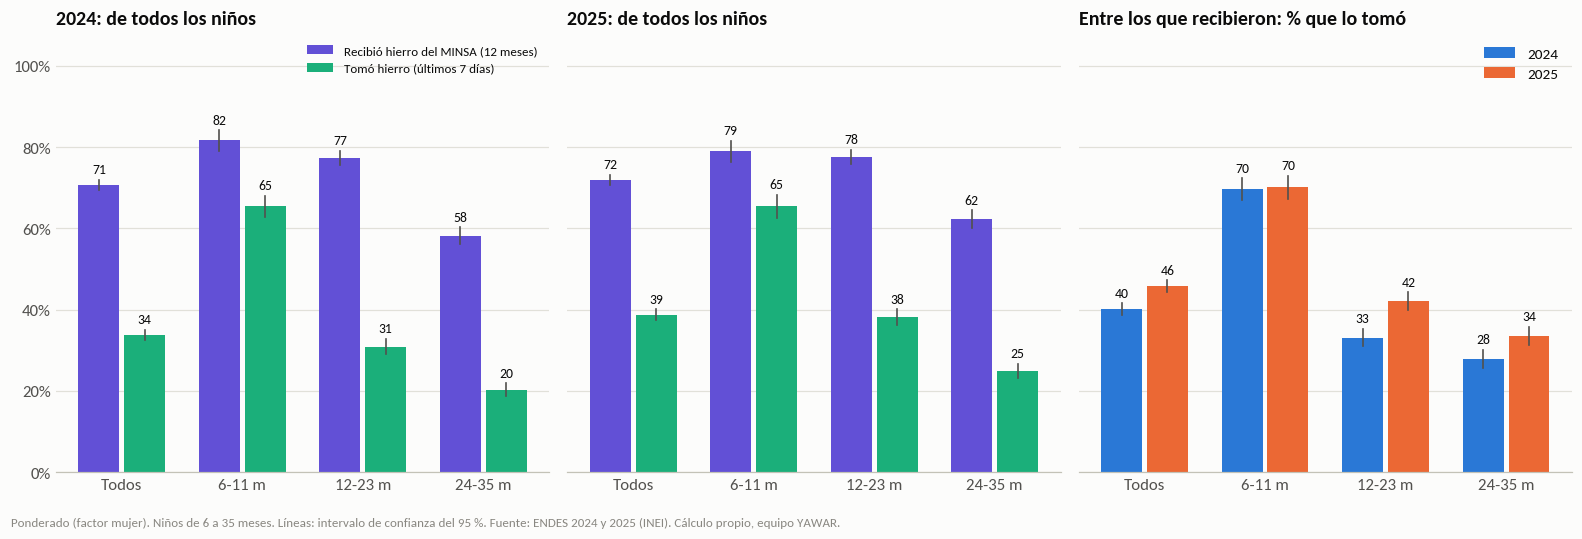

In [9]:
import matplotlib.pyplot as plt
import graficos as g

GX = [("Total", "Total", "Todos"), ("Edad (meses)", "6-11", "6-11 m"), ("Edad (meses)", "12-23", "12-23 m"), ("Edad (meses)", "24-35", "24-35 m")]
N_REC, N_TOMO, N_ENTRE = IND_HIERRO[0]["nombre"], IND_HIERRO[1]["nombre"], IND_HIERRO[2]["nombre"]

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.9), sharey=True)
for ax, anio in zip(axs[:2], (2024, 2025)):
    for ind, color, desp in ((N_REC, g.COLOR_RECIBIO, -0.19), (N_TOMO, g.COLOR_TOMO, 0.19)):
        for i, (tipo, grupo, _) in enumerate(GX):
            r = g.fila(hierro, ind, tipo, grupo, anio)
            g.barra_v(ax, i + desp, r["estimacion"], r["ic_inf"], r["ic_sup"], color, ancho=0.34)
            ax.text(i + desp, r["ic_sup"] + 1.6, f"{r['estimacion']:.0f}", ha="center", fontsize=9, color=g.TINTA)
    ax.set_title(f"{anio}: de todos los niños")
    ax.set_xticks(range(len(GX)))
    ax.set_xticklabels([x[2] for x in GX])
ax = axs[2]
for anio, desp in ((2024, -0.19), (2025, 0.19)):
    for i, (tipo, grupo, _) in enumerate(GX):
        r = g.fila(hierro, N_ENTRE, tipo, grupo, anio)
        g.barra_v(ax, i + desp, r["estimacion"], r["ic_inf"], r["ic_sup"], g.COLOR_ANIO[anio], ancho=0.34)
        ax.text(i + desp, r["ic_sup"] + 1.6, f"{r['estimacion']:.0f}", ha="center", fontsize=9, color=g.TINTA)
ax.set_title("Entre los que recibieron: % que lo tomó")
ax.set_xticks(range(len(GX)))
ax.set_xticklabels([x[2] for x in GX])
for ax in axs:
    ax.set_ylim(0, 108)
    g.rejilla(ax, "y")
    ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
g.leyenda(axs[0], [("Recibió hierro del MINSA (12 meses)", g.COLOR_RECIBIO), ("Tomó hierro (últimos 7 días)", g.COLOR_TOMO)], loc="upper right", fontsize=8.5)
g.leyenda(axs[2], [("2024", g.COLOR_ANIO[2024]), ("2025", g.COLOR_ANIO[2025])], loc="upper right")
g.pie(fig, "Ponderado (factor mujer). Niños de 6 a 35 meses. Líneas: intervalo de confianza del 95 %. Fuente: ENDES 2024 y 2025 (INEI). Cálculo propio, equipo YAWAR.")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Por departamento
Son 25 grupos de unos 200 a 450 niños cada uno por año; los intervalos son más anchos. La columna de fiabilidad marca las cifras que conviene tratar con cautela. Esta es la tabla que usará Camilla para los mapas.

In [10]:
for nombre in [IND_HIERRO[0]["nombre"], IND_HIERRO[2]["nombre"]]:
    print("=" * 110)
    print(nombre)
    t = ver(hierro, nombre, ["Departamento"])
    print(t.to_string(), "\n")

fi = hierro[(hierro["grupo_tipo"] == "Departamento") & (hierro["fiabilidad"] != "")]
print("Cifras por departamento marcadas con baja fiabilidad:", len(fi), "de", int((hierro["grupo_tipo"] == "Departamento").sum()))
print(fi.groupby(["indicador", "fiabilidad"]).size().to_string())

Recibió hierro del MINSA (12 meses)
                               % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo   grupo                                                            
Departamento Amazonas       83.0 (78.7–86.6)  84.4 (79.3–88.5)     423     417
             Apurímac       85.1 (80.4–88.9)  88.9 (84.7–92.1)     342     298
             Arequipa       61.3 (55.5–66.7)  64.0 (57.8–69.8)     355     328
             Ayacucho       85.3 (81.0–88.8)  85.8 (80.7–89.8)     388     360
             Cajamarca      83.2 (79.4–86.5)  88.7 (84.2–92.0)     376     273
             Callao         61.0 (55.9–65.8)  64.7 (59.0–70.0)     331     345
             Cusco          74.2 (68.0–79.5)  85.3 (79.8–89.5)     301     262
             Huancavelica   84.5 (79.1–88.8)  93.0 (88.2–95.9)     307     245
             Huánuco        85.4 (80.7–89.1)  84.6 (80.6–87.8)     417     403
             Ica            54.3 (48.8–59.8)  58.6 (53.5–63.6)     412     430
             Jun

### Gráfico: hierro por departamento
Un punto por departamento, ordenado de menor a mayor según el panel de la izquierda. **Naranja con línea = 2025 con su intervalo de confianza**; **círculo azul hueco = 2024** (sin intervalo, para no saturar). La línea gris vertical es el total nacional de 2025. Los intervalos por departamento son **anchos**: no interpretes diferencias pequeñas entre departamentos vecinos.

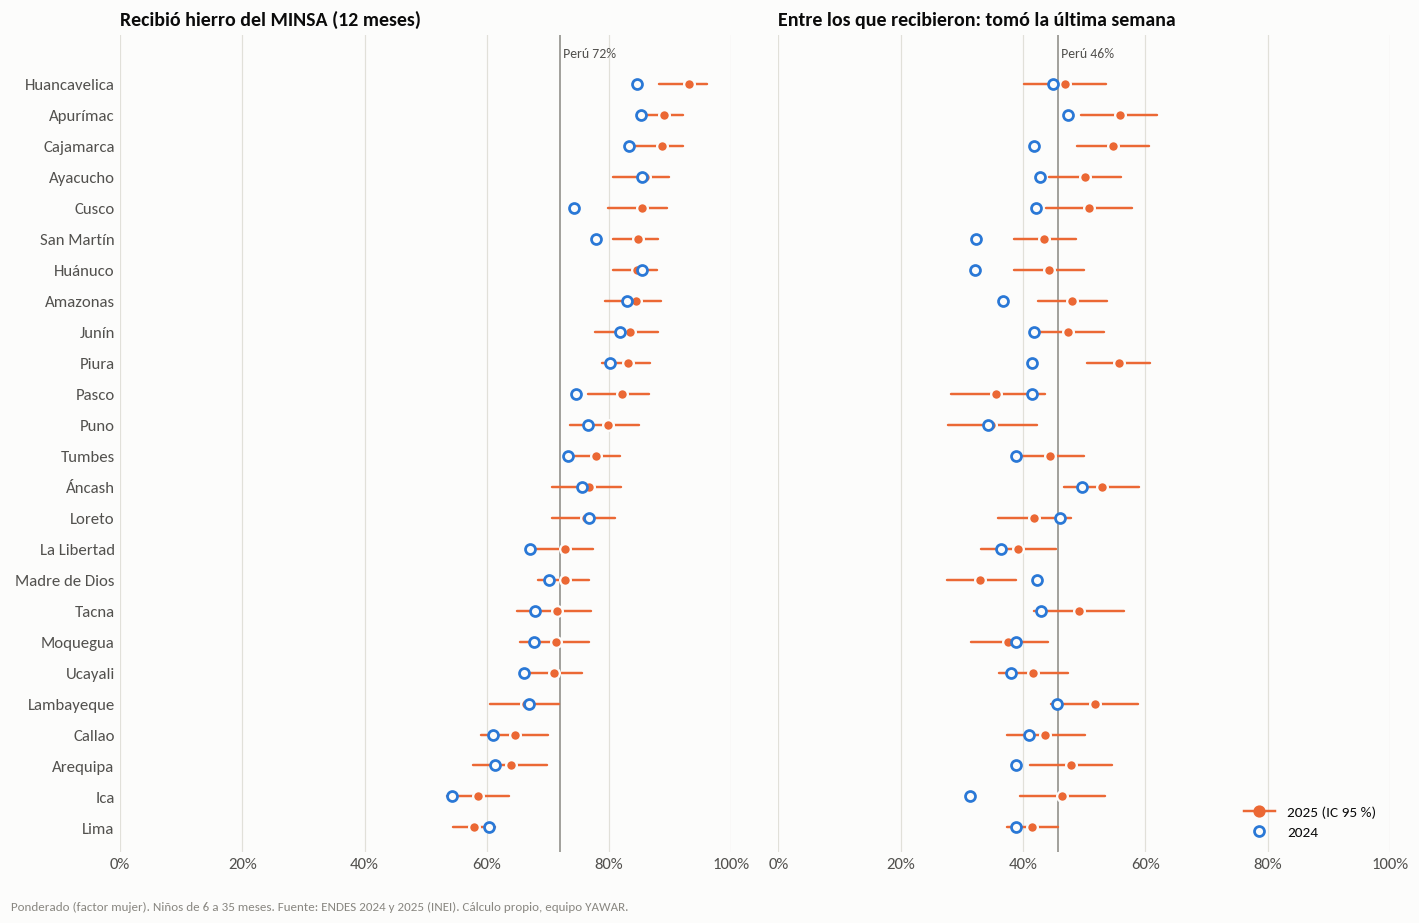

In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import graficos as g

def panel_departamentos(ax, indicador, titulo, orden):
    y = np.arange(len(orden))
    for yi, dep in zip(y, orden):
        r25, r24 = g.fila(hierro, indicador, "Departamento", dep, 2025), g.fila(hierro, indicador, "Departamento", dep, 2024)
        g.punto_ic(ax, r25["estimacion"], yi, r25["ic_inf"], r25["ic_sup"], g.COLOR_ANIO[2025], tam=7)
        ax.plot([r24["estimacion"]], [yi], "o", markerfacecolor=g.SUPERFICIE, markeredgecolor=g.COLOR_ANIO[2024], markeredgewidth=1.8, markersize=6.5, zorder=4)
    nac = g.fila(hierro, indicador, "Total", "Total", 2025)["estimacion"]
    ax.axvline(nac, color=g.APAGADO, linewidth=1, zorder=1)
    ax.text(nac, len(orden) - 0.2, f" Perú {nac:.0f}%", fontsize=9, color=g.TINTA2, va="bottom")
    ax.set_yticks(y)
    ax.set_yticklabels(orden)
    ax.set_ylim(-0.8, len(orden) + 0.6)
    ax.set_title(titulo)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
    g.rejilla(ax, "x")

orden_dep = (hierro[(hierro["indicador"] == N_REC) & (hierro["grupo_tipo"] == "Departamento") & (hierro["año"] == 2025)]
             .sort_values("estimacion")["grupo"].tolist())
fig, axs = plt.subplots(1, 2, figsize=(13, 8.4), sharey=True)
panel_departamentos(axs[0], N_REC, "Recibió hierro del MINSA (12 meses)", orden_dep)
panel_departamentos(axs[1], N_ENTRE, "Entre los que recibieron: tomó la última semana", orden_dep)
asas = [Line2D([], [], marker="o", color=g.COLOR_ANIO[2025], linewidth=1.6, markersize=7, label="2025 (IC 95 %)"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor=g.SUPERFICIE, markeredgecolor=g.COLOR_ANIO[2024], markeredgewidth=1.8, markersize=6.5, label="2024")]
axs[1].legend(handles=asas, loc="lower right")
g.pie(fig, "Ponderado (factor mujer). Niños de 6 a 35 meses. Fuente: ENDES 2024 y 2025 (INEI). Cálculo propio, equipo YAWAR.")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 6. ¿Importa qué factor de expansión usemos para el hierro?
La ficha técnica indica el factor hogar para anemia y el factor mujer para indicadores del cuestionario individual, pero no dice cuál corresponde al hierro de los niños. Comparamos los dos.

In [12]:
filas = []
for a in (2024, 2025):
    d = tablas[a]
    for ind in IND_HIERRO:
        base = np.asarray(ind["dominio"](d), dtype=bool)
        rm = diseno[(a, "mujer")].proporcion(ind["y"](d), base)
        rh = diseno[(a, "hogar")].proporcion(ind["y"](d), base)
        filas.append({"año": a, "indicador": ind["nombre"][:62], "factor mujer (%)": round(rm["estimacion"], 1),
                      "factor hogar (%)": round(rh["estimacion"], 1),
                      "diferencia (pp)": round(rh["estimacion"] - rm["estimacion"], 2)})
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))
print("\nDiferencia máxima entre los dos factores:", sens["diferencia (pp)"].abs().max(), "puntos porcentuales")

 año                                                      indicador  factor mujer (%)  factor hogar (%)  diferencia (pp)
2024                            Recibió hierro del MINSA (12 meses)              70.7              71.6             0.82
2024            Tomó hierro en los últimos 7 días (todos los niños)              33.9              33.8            -0.03
2024   Tomó hierro en los últimos 7 días (entre los que recibieron)              40.1              40.1            -0.01
2024 Recibió hierro y NO lo tomó la última semana (% de todos los n              42.3              42.8             0.49
2025                            Recibió hierro del MINSA (12 meses)              71.9              73.3             1.31
2025            Tomó hierro en los últimos 7 días (todos los niños)              38.8              39.1             0.29
2025   Tomó hierro en los últimos 7 días (entre los que recibieron)              45.8              46.0             0.17
2025 Recibió hierro y NO lo tomó

## 7. Anemia (ponderada, niños de 6 a 35 meses, tabla del hogar)

In [13]:
for nombre in [i["nombre"] for i in IND_ANEMIA]:
    print("=" * 110)
    print(nombre)
    print(ver(anem, nombre, ["Total", "Edad (meses)", "Área"]).to_string())
    print()

Anemia, criterio RM 363-2022-MINSA
                        % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo   grupo                                                     
Total        Total   43.9 (42.7–45.1)  43.7 (42.4–44.9)   10154    9511
Edad (meses) 6-11    67.3 (64.6–69.8)  66.1 (63.3–68.7)    2081    1955
             12-23   46.8 (44.9–48.6)  46.2 (44.2–48.2)    4010    3752
             24-35   29.1 (27.5–30.9)  29.4 (27.6–31.2)    4063    3804
Área         Urbano  40.3 (38.8–41.7)  40.7 (39.2–42.2)    6927    6765
             Rural   52.1 (49.9–54.3)  50.7 (48.3–53.1)    3227    2746

Anemia, criterio OMS 2024 / RM 251-2024-MINSA
                        % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo   grupo                                                     
Total        Total   35.5 (34.3–36.6)  35.1 (33.9–36.4)   10154    9511
Edad (meses) 6-11    52.0 (49.3–54.6)  48.9 (46.1–51.8)    2081    1955
             12-23   30.8 (29.1–32.5)  30.5 (28.7–32.4

### Gráfico: la anemia casi no cambió
Anemia en niños de 6 a 35 meses, por edad, en 2024 y 2025, con las dos definiciones oficiales. Los intervalos de 2024 y 2025 **se superponen en todos los grupos**: no hay un cambio distinguible. Esto no demuestra que el cambio sea cero; muestra que la encuesta no detecta uno.

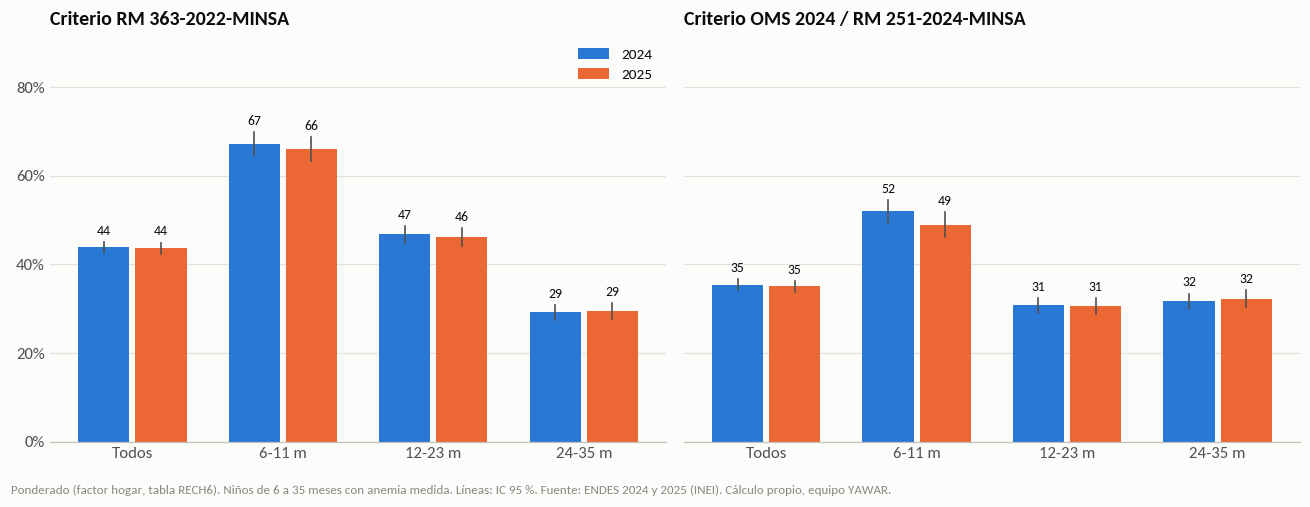

In [14]:
import matplotlib.pyplot as plt
import graficos as g

GA = [("Total", "Total", "Todos"), ("Edad (meses)", "6-11", "6-11 m"), ("Edad (meses)", "12-23", "12-23 m"), ("Edad (meses)", "24-35", "24-35 m")]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, ind, titulo in zip(axs, [i["nombre"] for i in IND_ANEMIA], ["Criterio RM 363-2022-MINSA", "Criterio OMS 2024 / RM 251-2024-MINSA"]):
    for anio, desp in ((2024, -0.19), (2025, 0.19)):
        for i, (tipo, grupo, _) in enumerate(GA):
            r = g.fila(anem, ind, tipo, grupo, anio)
            g.barra_v(ax, i + desp, r["estimacion"], r["ic_inf"], r["ic_sup"], g.COLOR_ANIO[anio], ancho=0.34)
            ax.text(i + desp, r["ic_sup"] + 1.6, f"{r['estimacion']:.0f}", ha="center", fontsize=9, color=g.TINTA)
    ax.set_xticks(range(len(GA)))
    ax.set_xticklabels([x[2] for x in GA])
    ax.set_ylim(0, 92)
    ax.set_title(titulo)
    g.rejilla(ax, "y")
    ax.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
g.leyenda(axs[0], [("2024", g.COLOR_ANIO[2024]), ("2025", g.COLOR_ANIO[2025])], loc="upper right")
g.pie(fig, "Ponderado (factor hogar, tabla RECH6). Niños de 6 a 35 meses con anemia medida. Líneas: IC 95 %. Fuente: ENDES 2024 y 2025 (INEI). Cálculo propio, equipo YAWAR.")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Anemia por departamento (criterio MINSA 2022)

In [15]:
print(ver(anem, IND_ANEMIA[0]["nombre"], ["Departamento"]).to_string())

                               % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo   grupo                                                            
Departamento Amazonas       47.5 (42.6–52.5)  43.6 (38.8–48.6)     444     422
             Apurímac       59.7 (53.9–65.2)  53.7 (47.8–59.5)     350     313
             Arequipa       45.0 (40.3–49.8)  40.0 (34.6–45.7)     333     304
             Ayacucho       50.9 (45.9–56.0)  54.1 (48.6–59.6)     403     368
             Cajamarca      38.5 (34.1–43.1)  35.3 (29.0–42.0)     382     281
             Callao         35.1 (29.6–41.1)  40.5 (35.7–45.6)     331     330
             Cusco          54.5 (46.9–61.9)  57.0 (49.9–63.9)     301     265
             Huancavelica   54.5 (48.4–60.4)  54.4 (47.5–61.3)     317     255
             Huánuco        45.6 (41.0–50.3)  45.3 (40.3–50.4)     440     414
             Ica            39.6 (34.8–44.5)  34.3 (29.5–39.4)     413     419
             Junín          50.4 (44.4–56.3)  47.8 (

## 8. Razones por las que no se consumió todo lo recibido
Recordatorio del cuaderno 03: esta pregunta se hace cuando la cantidad consumida es **menor** que la recibida, y no se refiere a la última semana. Las respuestas son **múltiples**, así que los porcentajes **suman más de 100**. Los porcentajes se calculan sobre los niños **a quienes se les preguntó** (recibieron hierro y la pregunta fue aplicada).

In [16]:
RAZONES = [("razon_estomago", "Le dolía el estómago"), ("razon_diarrea", "Le causó diarrea"),
           ("razon_estrenimiento", "Le causó estreñimiento"), ("razon_sabor", "El sabor es desagradable"),
           ("razon_dientes", "Le tiñó los dientes"), ("razon_orientacion", "Orientación a la madre no fue adecuada"),
           ("razon_olvido", "Se olvidó de darle"), ("razon_otra", "Otra"),
           ("razon_inicio_suplementacion", "Inició suplementación / continuador(a) (no es razón de no consumo)")]

recibio_u = lambda d: d["en_universo_6_35"] & (d["recibio"] == 1)
preguntada = lambda d: recibio_u(d) & d["razon_no_consumo_cod"].notna()
for a, d in tablas.items():
    d["fue_preguntada"] = d["razon_no_consumo_cod"].notna().astype(float)

IND_RAZONES = [dict(nombre="Se les preguntó por las razones (% de los que recibieron hierro)", y=lambda d: d["fue_preguntada"], dominio=recibio_u, peso="mujer")]
for col, texto in RAZONES:
    IND_RAZONES.append(dict(nombre=texto, y=(lambda c: (lambda d: d[c]))(col), dominio=preguntada, peso="mujer"))

razones = calcular(IND_RAZONES, tablas, diseno)
razones_sin_depto = razones[razones["grupo_tipo"] != "Departamento"]
print(ver(razones_sin_depto, IND_RAZONES[0]["nombre"], ["Total"]).to_string(), "\n")
print("Razones (% de los niños a quienes se les preguntó; respuesta múltiple), solo Total:")
tt = pd.concat([ver(razones_sin_depto, i["nombre"], ["Total"]).assign(razón=i["nombre"]) for i in IND_RAZONES[1:]]).reset_index(drop=True)
print(tt[["razón", "% 2024 (IC95)", "% 2025 (IC95)", "n 2024", "n 2025"]].to_string(index=False))

                     % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo grupo                                                    
Total      Total  71.2 (69.8–72.6)  72.8 (71.5–74.1)    7347    7175 

Razones (% de los niños a quienes se les preguntó; respuesta múltiple), solo Total:
                                                             razón    % 2024 (IC95)    % 2025 (IC95)  n 2024  n 2025
                                              Le dolía el estómago    0.7 (0.4–1.2)    0.8 (0.5–1.1)    5293    5283
                                                  Le causó diarrea    2.5 (2.0–3.1)    2.0 (1.6–2.5)    5293    5283
                                            Le causó estreñimiento 22.0 (20.5–23.6) 21.8 (20.3–23.2)    5293    5283
                                          El sabor es desagradable 34.8 (33.2–36.4) 32.5 (30.9–34.1)    5293    5283
                                               Le tiñó los dientes    5.1 (4.5–5.9)    6.0 (5.3–6.8)    5293    5283
     

### Razones, quitando el código G
El código G ("inició suplementación / continuador(a)") no es una razón de no consumo: describe a niños que todavía están usando el hierro. Pesa mucho en la tabla de arriba, así que repetimos el cálculo **entre quienes dieron al menos una razón distinta de G**, que es lo que realmente describe por qué no se consumió el hierro.

In [17]:
solo_g = lambda d: preguntada(d) & (d["razon_no_consumo_cod"] == "G")
con_razon = lambda d: preguntada(d) & (d["razon_no_consumo_cod"] != "G")
for a, d in tablas.items():
    d["respondio_solo_g"] = (d["razon_no_consumo_cod"] == "G").astype(float).where(d["razon_no_consumo_cod"].notna())

IND_RAZONES2 = [dict(nombre="Respondieron ÚNICAMENTE el código G (% de los que se les preguntó)", y=lambda d: d["respondio_solo_g"], dominio=preguntada, peso="mujer")]
for col, texto in RAZONES:
    if col != "razon_inicio_suplementacion":
        IND_RAZONES2.append(dict(nombre=texto, y=(lambda c: (lambda d: d[c]))(col), dominio=con_razon, peso="mujer"))

razones2 = calcular(IND_RAZONES2, tablas, diseno)
r2 = razones2[razones2["grupo_tipo"] != "Departamento"]
print(ver(r2, IND_RAZONES2[0]["nombre"], ["Total"]).to_string(), "\n")
print("Razones (% de los niños que dieron al menos una razón distinta de G; respuesta múltiple), Total:")
t2 = pd.concat([ver(r2, i["nombre"], ["Total"]).assign(razón=i["nombre"]) for i in IND_RAZONES2[1:]]).reset_index(drop=True)
print(t2[["razón", "% 2024 (IC95)", "% 2025 (IC95)", "n 2024", "n 2025"]].to_string(index=False))

                     % 2024 (IC95)     % 2025 (IC95)  n 2024  n 2025
grupo_tipo grupo                                                    
Total      Total  30.7 (29.1–32.4)  34.7 (33.0–36.4)    5293    5283 

Razones (% de los niños que dieron al menos una razón distinta de G; respuesta múltiple), Total:
                                 razón    % 2024 (IC95)    % 2025 (IC95)  n 2024  n 2025
                  Le dolía el estómago    1.0 (0.6–1.7)    1.2 (0.8–1.7)    3712    3510
                      Le causó diarrea    3.6 (2.9–4.4)    3.1 (2.4–3.9)    3712    3510
                Le causó estreñimiento 31.8 (29.8–33.9) 33.3 (31.3–35.4)    3712    3510
              El sabor es desagradable 50.2 (48.1–52.3) 49.8 (47.7–51.9)    3712    3510
                   Le tiñó los dientes    7.4 (6.4–8.5)   9.2 (8.2–10.4)    3712    3510
Orientación a la madre no fue adecuada    2.4 (1.9–3.2)    2.0 (1.5–2.6)    3712    3510
                    Se olvidó de darle 11.4 (10.1–12.8)  10.8 (9.5–12.1

### Gráfico: razones por las que no se consumió todo el hierro recibido
Entre los niños que dieron al menos una razón distinta de G (respuesta múltiple: los porcentajes suman más de 100). Ordenado de mayor a menor según 2025. Líneas finas: intervalo de confianza del 95 %.

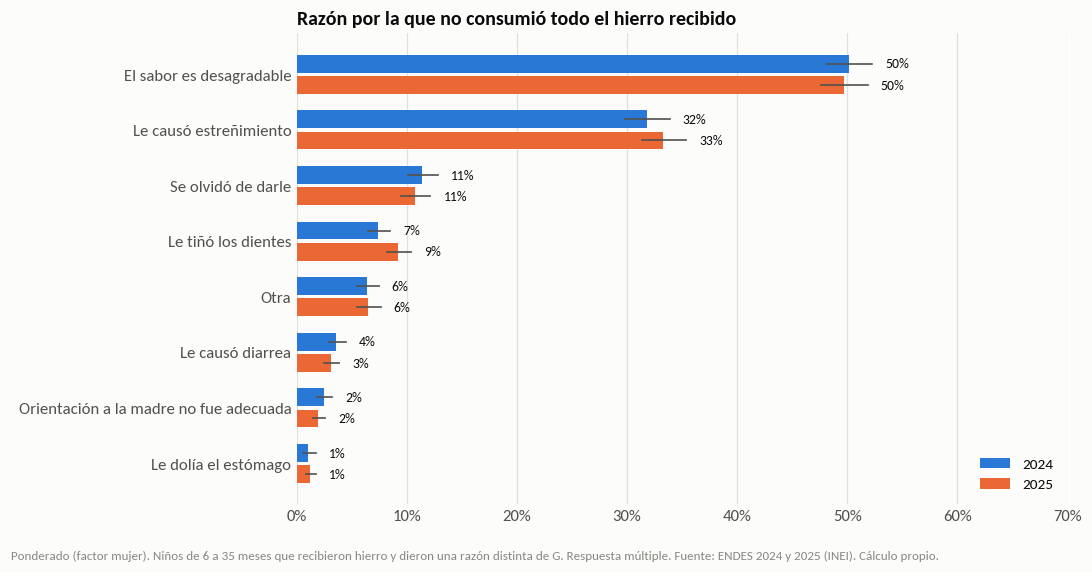

In [18]:
import matplotlib.pyplot as plt
import graficos as g

N_R = [i["nombre"] for i in IND_RAZONES2[1:]]
v25 = [g.fila(razones2, n, "Total", "Total", 2025)["estimacion"] for n in N_R]
orden = list(np.argsort(v25))
fig, ax = plt.subplots(figsize=(10, 5.2))
for pos, k in enumerate(orden):
    for anio, desp in ((2024, 0.19), (2025, -0.19)):
        r = g.fila(razones2, N_R[k], "Total", "Total", anio)
        ax.barh(pos + desp, r["estimacion"], height=0.32, color=g.COLOR_ANIO[anio], zorder=2)
        ax.plot([r["ic_inf"], r["ic_sup"]], [pos + desp] * 2, color=g.TINTA2, linewidth=1.1, zorder=3)
        ax.text(r["ic_sup"] + 1.2, pos + desp, f"{r['estimacion']:.0f}%", va="center", fontsize=9, color=g.TINTA)
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([N_R[k] for k in orden])
ax.set_xlim(0, 70)
ax.xaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
g.rejilla(ax, "x")
ax.set_title("Razón por la que no consumió todo el hierro recibido")
g.leyenda(ax, [("2024", g.COLOR_ANIO[2024]), ("2025", g.COLOR_ANIO[2025])], loc="lower right")
g.pie(fig, "Ponderado (factor mujer). Niños de 6 a 35 meses que recibieron hierro y dieron una razón distinta de G. Respuesta múltiple. Fuente: ENDES 2024 y 2025 (INEI). Cálculo propio.")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 9. Cambio entre 2024 y 2025
Diferencia en puntos porcentuales con su intervalo del 95 %. **Supuesto:** tratamos las dos encuestas como independientes. Como cerca del 64 % de los niños de 2025 vive en conglomerados que también estaban en 2024, el intervalo de la diferencia es, si algo, **más ancho de lo necesario** (conservador). Es decir, si una diferencia sale significativa aquí, lo es.

In [19]:
todas = pd.concat([hierro, anem], ignore_index=True)
dif = diferencias(todas)

def ver_dif(dif, tipos):
    s = dif[dif["grupo_tipo"].isin(tipos)].copy()
    s["2024"] = s["estimacion_2024"].round(1)
    s["2025"] = s["estimacion_2025"].round(1)
    s["cambio (IC95)"] = s.apply(lambda r: f"{r['cambio_pp']:+.1f} ({r['ic_inf']:+.1f} a {r['ic_sup']:+.1f})", axis=1)
    return s[["indicador", "grupo_tipo", "grupo", "2024", "2025", "cambio (IC95)", "p_valor", "distinto_de_0"]].round({"p_valor": 3})

print("=== Cambio 2024 -> 2025, total nacional ===")
print(ver_dif(dif, ["Total"]).drop(columns=["grupo_tipo", "grupo"]).to_string(index=False))
print("\n=== Cambio 2024 -> 2025, por edad ===")
print(ver_dif(dif, ["Edad (meses)"]).drop(columns=["grupo_tipo"]).to_string(index=False))

=== Cambio 2024 -> 2025, total nacional ===
                                                          indicador  2024  2025      cambio (IC95)  p_valor distinto_de_0
                                Recibió hierro del MINSA (12 meses)  70.7  71.9 +1.2 (-0.6 a +3.0)    0.192            no
                Tomó hierro en los últimos 7 días (todos los niños)  33.9  38.8 +4.9 (+3.2 a +6.7)    0.000            sí
       Tomó hierro en los últimos 7 días (entre los que recibieron)  40.1  45.8 +5.6 (+3.6 a +7.7)    0.000            sí
Recibió hierro y NO lo tomó la última semana (% de todos los niños)  42.3  39.0 -3.3 (-5.1 a -1.6)    0.000            sí
                                 Anemia, criterio RM 363-2022-MINSA  43.9  43.7 -0.2 (-2.0 a +1.5)    0.790            no
                      Anemia, criterio OMS 2024 / RM 251-2024-MINSA  35.5  35.1 -0.3 (-2.0 a +1.3)    0.688            no

=== Cambio 2024 -> 2025, por edad ===
                                                          indic

### Gráfico: cambio 2024 → 2025 en el total nacional
Cada punto es la diferencia (2025 − 2024) en puntos porcentuales, con su intervalo de confianza del 95 %. **Azul = el intervalo no incluye el cero** (cambio distinguible); **gris = incluye el cero** (no se puede distinguir de "no cambió"). Recuerda el supuesto de independencia: el intervalo es, si algo, más ancho de lo necesario.

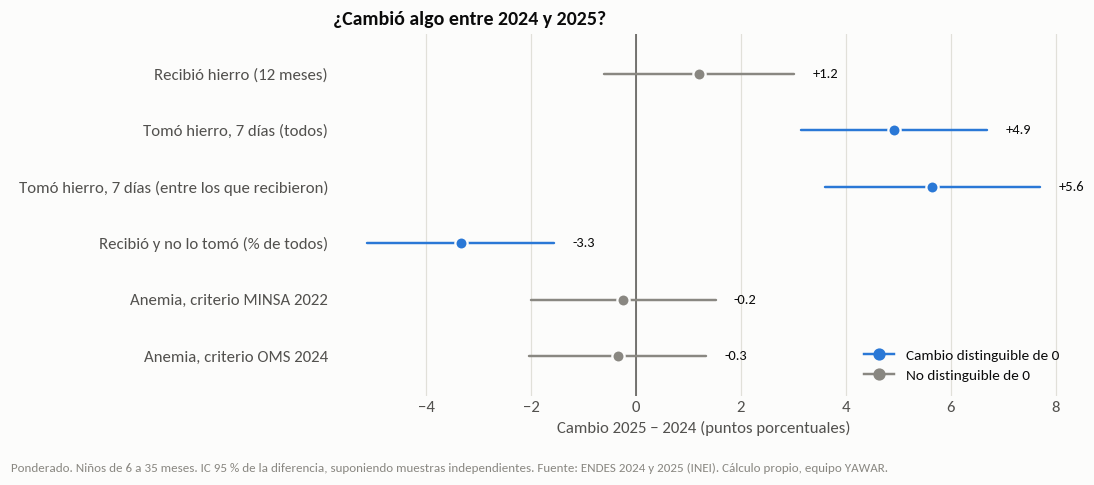

In [20]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import graficos as g

NOMBRES = [i["nombre"] for i in IND_HIERRO + IND_ANEMIA]
CORTO = ["Recibió hierro (12 meses)", "Tomó hierro, 7 días (todos)", "Tomó hierro, 7 días (entre los que recibieron)",
         "Recibió y no lo tomó (% de todos)", "Anemia, criterio MINSA 2022", "Anemia, criterio OMS 2024"]
tot = dif[dif["grupo_tipo"] == "Total"].set_index("indicador").loc[NOMBRES]
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(NOMBRES))[::-1]
for yi, (_, r) in zip(y, tot.iterrows()):
    color = g.AZUL if r["distinto_de_0"] == "sí" else g.APAGADO
    g.punto_ic(ax, r["cambio_pp"], yi, r["ic_inf"], r["ic_sup"], color, tam=8)
    ax.text(r["ic_sup"] + 0.35, yi, f"{r['cambio_pp']:+.1f}", va="center", fontsize=9.5, color=g.TINTA)
ax.axvline(0, color=g.TINTA2, linewidth=1, zorder=1)
ax.set_yticks(y)
ax.set_yticklabels(CORTO)
ax.set_xlabel("Cambio 2025 − 2024 (puntos porcentuales)")
ax.set_ylim(-0.7, len(NOMBRES) - 0.3)
g.rejilla(ax, "x")
ax.set_title("¿Cambió algo entre 2024 y 2025?")
ax.legend(handles=[Line2D([], [], marker="o", color=g.AZUL, linewidth=1.6, markersize=7, label="Cambio distinguible de 0"),
                   Line2D([], [], marker="o", color=g.APAGADO, linewidth=1.6, markersize=7, label="No distinguible de 0")], loc="lower right")
g.pie(fig, "Ponderado. Niños de 6 a 35 meses. IC 95 % de la diferencia, suponiendo muestras independientes. Fuente: ENDES 2024 y 2025 (INEI). Cálculo propio, equipo YAWAR.")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 10. Guardar los resultados
Se guardan en `analisis/resultados/` como tablas de cifras (no contienen datos de personas, solo porcentajes), por lo que **sí pueden subirse al repositorio**. Son la fuente de las cifras del pitch, de la ficha y de los mapas de Camilla.

In [21]:
RESULTADOS.mkdir(parents=True, exist_ok=True)
columnas = ["indicador", "grupo_tipo", "grupo", "año", "peso", "estimacion", "ic_inf", "ic_sup", "se", "deff", "n", "n_upm", "fiabilidad"]
renombrar = {"estimacion": "estimacion_pct", "ic_inf": "ic95_inf_pct", "ic_sup": "ic95_sup_pct", "se": "error_estandar_pp",
             "n": "n_ninos_sin_ponderar", "n_upm": "n_conglomerados", "peso": "factor_usado"}
cifras = pd.concat([hierro, anem], ignore_index=True)[columnas].rename(columns=renombrar).round(3)
cifras["universo"] = "Niños de 6 a 35 meses"
cifras["ponderada"] = "sí"
cifras.to_csv(RESULTADOS / "cifras_ponderadas.csv", index=False, encoding="utf-8-sig")
razones[columnas].rename(columns=renombrar).round(3).assign(universo="Niños de 6 a 35 meses que recibieron hierro y a quienes se les preguntó", ponderada="sí").to_csv(
    RESULTADOS / "razones_no_consumo.csv", index=False, encoding="utf-8-sig")
razones2[columnas].rename(columns=renombrar).round(3).assign(universo="Niños de 6 a 35 meses que recibieron hierro y dieron una razón distinta de G", ponderada="sí").to_csv(
    RESULTADOS / "razones_no_consumo_sin_G.csv", index=False, encoding="utf-8-sig")
dif.round(3).to_csv(RESULTADOS / "diferencias_2024_2025.csv", index=False, encoding="utf-8-sig")
for f in sorted(RESULTADOS.glob("*.csv")):
    print(f"Guardado: analisis/resultados/{f.name}  ({len(pd.read_csv(f))} filas)")

Guardado: analisis/resultados/cifras_ponderadas.csv  (404 filas)
Guardado: analisis/resultados/diferencias_2024_2025.csv  (202 filas)
Guardado: analisis/resultados/para_camilla_departamentos.csv  (344 filas)
Guardado: analisis/resultados/para_gian_proporciones_departamento.csv  (624 filas)
Guardado: analisis/resultados/razones_no_consumo.csv  (700 filas)
Guardado: analisis/resultados/razones_no_consumo_sin_G.csv  (630 filas)
Guardado: analisis/resultados/tabla1_2024_2025.csv  (36 filas)


## 11. Conclusiones y pendientes

### Qué se verificó (por qué se puede confiar en estas cifras)
1. **Cinco pruebas internas del estimador** pasaron (proporción, error estándar clásico, invarianza de escala, subpoblación y conglomerados homogéneos).
2. **Reproduce las cifras oficiales de INEI** con diferencias de 0,0 a 0,3 puntos; todas las cifras de INEI caen dentro de nuestros intervalos.
3. **Un método independiente (jackknife) da el mismo error estándar** (diferencia máxima de 0,0012 puntos en seis casos).
4. **Límite de la validación:** en anemia, nuestro valor queda 0,2 a 0,3 puntos por encima de INEI de forma sistemática. No logré explicarlo (no es la definición de edad ni el universo de niños). Es mucho menor que el margen de error (±1,2 puntos), pero **no puedo afirmar que sea idéntico a INEI**. No pude contrastar con R ni con `samplics`.

### Cifras principales (ponderadas, niños de 6 a 35 meses; entre paréntesis, intervalo de confianza del 95 %)
| Indicador | 2024 | 2025 | Cambio |
|---|---|---|---|
| Recibió hierro del MINSA en 12 meses | 70,7 % (69,5–72,0) | 71,9 % (70,6–73,2) | +1,2 pp, no distinguible de 0 |
| Tomó hierro la última semana (todos los niños) | 33,9 % (32,7–35,1) | 38,8 % (37,5–40,1) | **+4,9 pp** (+3,2 a +6,7) |
| Tomó hierro la última semana (entre los que recibieron) | 40,1 % (38,7–41,6) | 45,8 % (44,3–47,3) | **+5,6 pp** (+3,6 a +7,7) |
| Recibió hierro y NO lo tomó la última semana (% de todos) | 42,3 % (41,1–43,6) | 39,0 % (37,7–40,3) | **−3,3 pp** (−5,1 a −1,6) |
| Anemia, criterio RM 363-2022-MINSA | 43,9 % (42,7–45,1) | 43,7 % (42,4–44,9) | −0,2 pp, no distinguible de 0 |
| Anemia, criterio OMS 2024 | 35,5 % (34,3–36,6) | 35,1 % (33,9–36,4) | −0,3 pp, no distinguible de 0 |

### Qué dicen estos resultados
- **La anemia no cambió de forma detectable entre 2024 y 2025**, con cualquiera de las dos definiciones. Esto respalda la frase "la anemia casi no bajó", con la salvedad de que se demuestra que **no hay un cambio distinguible**, no que sea exactamente cero.
- **El consumo de hierro sí mejoró:** más niños lo tomaron la última semana (+4,9 pp) y menos niños recibieron hierro sin tomarlo (−3,3 pp). La mejora se concentra en los niños de 12 a 23 meses (+7,2 pp) y de 24 a 35 meses (+4,6 pp); en los de 6 a 11 meses no cambió. Esto **matiza el planteamiento del equipo**: el problema persiste, pero no está empeorando.
- **Entre los niños que recibieron hierro, más de la mitad no lo tomó la última semana** (54,2 % en 2025; 59,9 % en 2024). Recordar que "no tomó la última semana" no equivale a abandono: un niño que ya terminó su esquema también aparece así.
- **La caída con la edad se confirma (2025):** entre los que recibieron, tomaron la última semana el 70,1 % de los de 6 a 11 meses, el 42,1 % de los de 12 a 23 y el 33,6 % de los de 24 a 35.
- **Quién recibe hierro:** más en el área rural (87,7 %) que en la urbana (66,5 %), y menos en Lima Metropolitana (56,8 %). Entre departamentos, en 2025 el menor porcentaje de "recibió" está en Ica (58,6 %) y Lima (57,9 %).
- **La anemia depende mucho de la edad:** 66,1 % en niños de 6 a 11 meses frente a 29,4 % en los de 24 a 35 (criterio MINSA, 2025). Puno destaca con 75,1 %.
- **Razones de no consumo** (entre quienes dieron al menos una razón distinta de G): el sabor desagradable (≈50 %), el estreñimiento (≈32 a 33 %), el olvido (≈11 %) y manchar los dientes (7 a 9 %). Entre los niños a quienes se les preguntó, el 31 % (2024) y el 35 % (2025) respondió **únicamente** el código G, es decir, aún están usando el hierro y no lo terminaron.
- **Para el asistente de WhatsApp (sugerencia, a validar con el asesor de salud):** las opciones del plan ("no le gusta", "estreñimiento", "se me olvidó", "otro") coinciden con las razones más frecuentes de ENDES. "Se acabó" no es una razón de esta pregunta (en ENDES aparece como razón para no *recibir*), y "le mancha los dientes" tiene una frecuencia comparable a otras.

### Reservas que debes mantener al presentar estas cifras
- **El factor de expansión del hierro no está fijado por la ficha técnica.** Con el factor hogar en lugar del mujer, "recibió" sube hasta 1,3 puntos (73,3 % frente a 71,9 % en 2025); "tomó" cambia menos de 0,3 puntos. Usamos el factor mujer.
- **Comparaciones múltiples:** hay unas 200 diferencias por grupo en `diferencias_2024_2025.csv`. Con tantas, algunas saldrán "distintas de 0" solo por azar. Confía en los totales y en patrones que se repitan, no en un departamento aislado.
- **La anemia 2025 de INEI (43,4 %) que usé para validar viene de una nota de prensa** (Infobae, que cita a INEI), no de la publicación de INEI. Antes de citar una cifra oficial de 2025 en la ficha, hay que abrir la publicación original.
- **No se calcularon totales** de niños, solo porcentajes.

### Pendientes
| Pendiente | Quién | Cómo se cierra |
|---|---|---|
| Fijar qué factor usar para el hierro (mujer u hogar) | Magno | Buscar en la publicación de INEI un indicador de "recibió hierro" para contrastar |
| Obtener la publicación oficial de INEI de 2025 para citar la cifra de anemia | Magno | Descargarla del portal de INEI y revisar el cuadro del indicador |
| Elegir qué definición de anemia presentar (MINSA 2022 u OMS 2024) | Magno y Camilla | Preguntar al asesor de salud cuál es la vigente |
| Pasar las cifras por departamento a Camilla (mapas) y las proporciones de edad y área a Gian (padrón simulado) | Magno | Compartir `analisis/resultados/` |
| Avisar a Jose de la frecuencia ponderada de la etiqueta "no tomó" (59,9 % en 2024 y 54,2 % en 2025 entre los que recibieron) | Magno | Mensaje al equipo |
| Pasar a Arny los hallazgos sobre las opciones del asistente | Magno | Mensaje al equipo, con el asesor de salud como validación |

**Siguiente cuaderno:** `05_table1_y_graficos`, con la "Table 1" de 2024 frente a 2025 y los 3 o 4 gráficos del pitch.